# Latent lesion study

Damage some latent tokens, decode, and ask two questions:

* **(a) inside the hole:** is the damaged region recovered, and is it recovered as *texture* or only as smooth continuation?
* **(b) around the hole:** how far does the damage spread? (the decoder's large-perturbation receptive field; how far a wrong generated token pollutes its surroundings)

Zero is a poor "missing" value (some decoders turn it into flat patches, others into texture), so we compare a **family of fills**:
`zero`, `mean`, `neg` (2c-y: reflected through the channel centre, same magnitude, opposite content), `neg0` (literal -y), `noise`, `shuffle`
(real latents from the wrong place), `neighbor` (latent-space interpolation).

**Models.** If pretrained CompressAI weights can be downloaded, they are used (`bmshj2018_factorized`, `mbt2018_mean`).
Otherwise the notebook falls back to a **toy** autoencoder trained for ~1 minute on four sample images; the conclusions then concern the method, not real codecs.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings('ignore')
import numpy as np, torch, matplotlib.pyplot as plt
from skimage import data, transform
sys.path.insert(0, str(pathlib.Path('..').resolve() / 'examples'))
from receptive_field_scope.lesion import (make_mask, apply_fill, lesion_latents, damage_profile, hole_sweep, psnr,
                                          lesion_importance_map, harmonic_fill, upsample_mask, radial_power, highfreq_ratio, FILLS)
torch.manual_seed(0); plt.rcParams['figure.dpi'] = 110

def to_tensor(img, size=256):
    return torch.tensor(transform.resize(img, (size, size), anti_aliasing=True), dtype=torch.float32).permute(2, 0, 1)[None]
imgs = [to_tensor(data.astronaut()), to_tensor(data.coffee()), to_tensor(data.chelsea()), to_tensor(data.rocket())]
image = imgs[0]
show = lambda t: t[0].detach().permute(1, 2, 0).clamp(0, 1).numpy()

In [21]:
class Codec:
    '''Uniform interface: encode(x) -> y [N,C,h,w]; decode(y) -> x; quantize(y); cell = pixels per token.'''
    def __init__(self, name, enc, dec, quantize=torch.round, cell=16):
        self.name, self.enc, self.dec, self.quantize, self.cell = name, enc, dec, quantize, cell

def load_codecs():
    codecs = []
    try:
        from compressai.zoo import bmshj2018_factorized, mbt2018_mean, cheng2020_anchor
        for name, ctor in [('bmshj2018_factorized(q=3)', lambda: bmshj2018_factorized(quality=3, pretrained=True)),
                           ('mbt2018_mean(q=6)', lambda: mbt2018_mean(quality=6, pretrained=True)),
                           ('cheng2020_anchor(quality=6)', lambda: cheng2020_anchor(quality=6, pretrained=True))
                           ]:
            m = ctor().eval()
            codecs.append(Codec(name, m.g_a, m.g_s, torch.round, 16))
        print('using pretrained CompressAI weights')
    except IOError as e:
        print('pretrained CompressAI unavailable here (', type(e).__name__, ') -> training the TOY autoencoder')
        from tiny_autoencoder import train_tiny_autoencoder
        m = train_tiny_autoencoder(imgs, steps=900, verbose=False)
        codecs.append(Codec('toy AE (stride 8)', m.enc, m.dec, torch.round, 8))
    return codecs

codecs = load_codecs()
codec = codecs[-1]
with torch.no_grad():
    y = codec.enc(image)
print(codec.name, 'latents', tuple(y.shape), '| fraction of latents that round to 0:', float((torch.round(y) == 0).float().mean()))

using pretrained CompressAI weights
cheng2020_anchor(quality=6) latents (1, 192, 16, 16) | fraction of latents that round to 0: 0.6906941533088684


## 1. The lattice experiment, with different fills

`y[:, :, ::2, ::2] = fill`, then decode. PSNR is measured **against the un-lesioned quantized decode** (the baseline), not the original, so the quantization floor is not counted as damage.

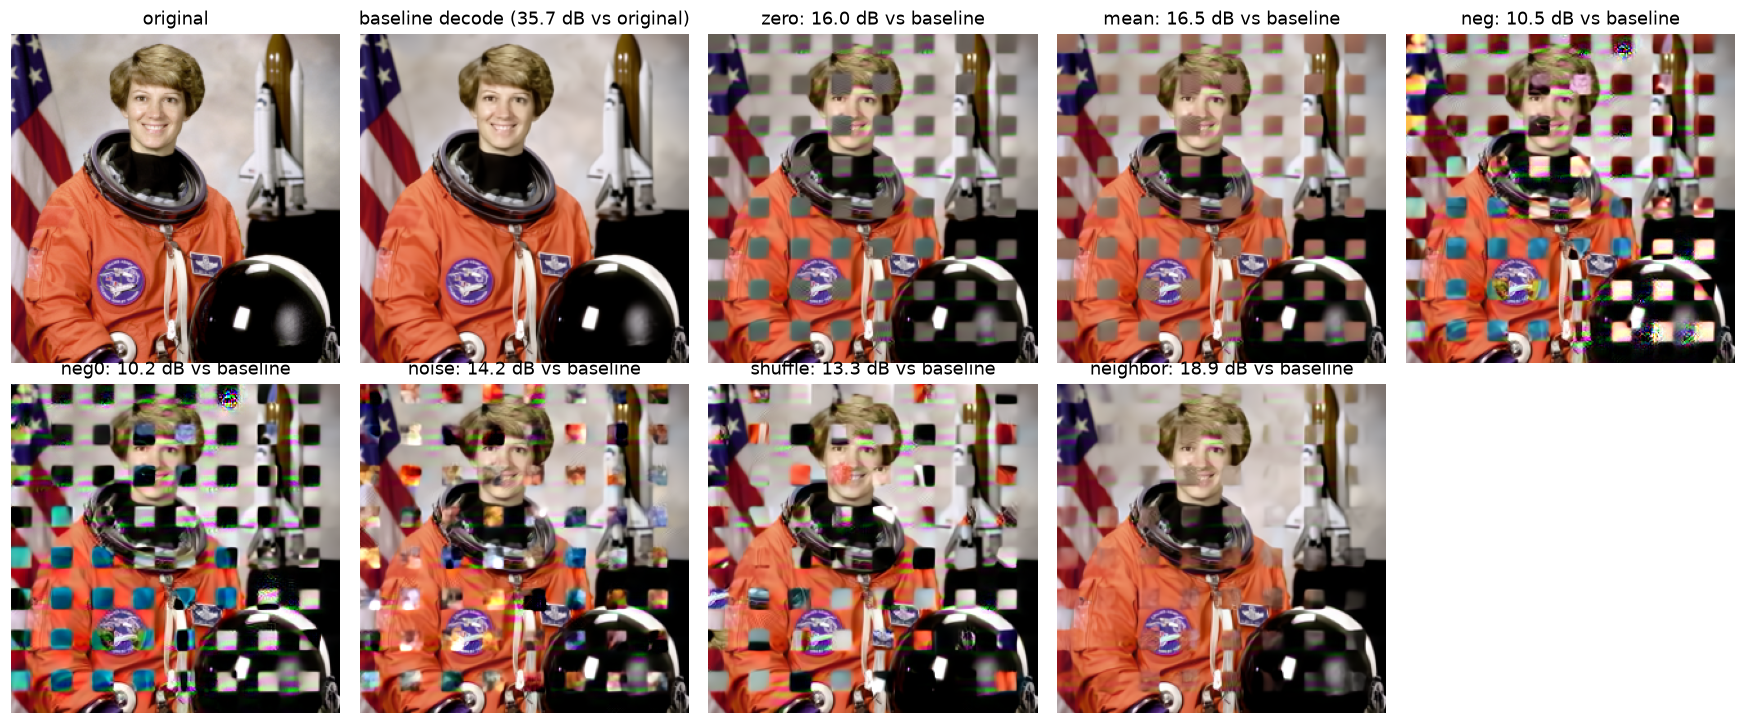

In [22]:
mask = make_mask(y.shape[-2:], 'lattice', step=2)
fills = ['zero', 'mean', 'neg', 'neg0', 'noise', 'shuffle', 'neighbor']
outs = {f: lesion_latents(codec.dec, y, mask, f, quantize=codec.quantize) for f in fills}
base = outs['zero']['baseline']
fig, axes = plt.subplots(2, 5, figsize=(16, 6.6))
axes[0, 0].imshow(show(image)); axes[0, 0].set_title('original')
axes[0, 1].imshow(show(base)); axes[0, 1].set_title(f'baseline decode ({psnr(base, image):.1f} dB vs original)')
for ax, f in zip(list(axes.flat)[2:], fills):
    o = outs[f]['lesioned']
    ax.imshow(show(o)); ax.set_title(f'{f}: {psnr(o, base):.1f} dB vs baseline')
for ax in axes.flat: ax.axis('off')
plt.tight_layout();

## 2. Damage versus distance

A **dense lattice cannot give a distance profile**: with `::2` every intact token is exactly 1 cell from a lesioned one (and vice versa), so every point would sit at distance 1 / depth 1 (`damage_profile` now warns about this).
For profiles we use a single **block hole** (8x8 tokens): its surroundings give distances 1..8 and its interior gives depths 1..4.

* **outside** (solid): mean squared change in pixels `d` token-cells from the nearest lesioned token: *collateral damage*.
* **inside** (dashed): change in lesioned cells at depth `k` (cells from the nearest intact token): *how well the hole heals*.

A strictly local decoder drops to **exactly zero** beyond its reach. Agreement between fills means the curve is a property of the decoder; spread between fills means it is a property of the fill.

fill       inside dmg  ring-1 dmg  far frac  err in (lesioned)  err in (baseline)
zero          0.10792     0.00151     0.006            0.10816            0.00038
mean          0.09319     0.00110     0.007            0.09339            0.00038
neg           0.36004     0.00444     0.003            0.36023            0.00038
neg0              inf 88604755585106869062132811431936.00000     0.468                inf            0.00038
noise         0.17514     0.00239     0.005            0.17532            0.00038
shuffle       0.15960     0.00239     0.006            0.15985            0.00038
neighbor      0.08884     0.00093     0.012            0.08906            0.00038


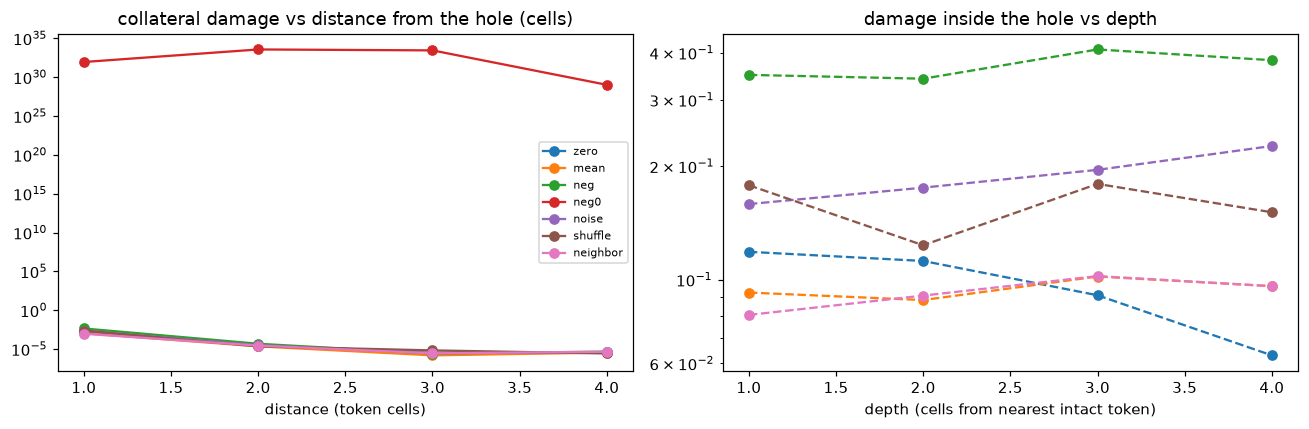

In [23]:
mask_blk = make_mask(y.shape[-2:], 'block', size=(8, 8))
outs_b = {f: lesion_latents(codec.dec, y, mask_blk, f, quantize=codec.quantize) for f in fills}
profs = {f: damage_profile(outs_b[f]['baseline'], outs_b[f]['lesioned'], mask_blk, original=image, maxd=8) for f in fills}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for f in fills:
    p = profs[f]
    ax[0].semilogy(p['outside_dist_cells'], p['outside_damage'].clamp_min(1e-12), 'o-', label=f)
    ax[1].semilogy(p['inside_depth_cells'][:4], p['inside_damage'][:4].clamp_min(1e-12), 'o--', label=f)
ax[0].set_title('collateral damage vs distance from the hole (cells)'); ax[0].set_xlabel('distance (token cells)')
ax[1].set_title('damage inside the hole vs depth'); ax[1].set_xlabel('depth (cells from nearest intact token)')
ax[0].legend(fontsize=7); plt.tight_layout()
print(f"{'fill':9s} {'inside dmg':>11s} {'ring-1 dmg':>11s} {'far frac':>9s} {'err in (lesioned)':>18s} {'err in (baseline)':>18s}")
for f in fills:
    p = profs[f]
    print(f"{f:9s} {p['damage_inside_mean']:11.5f} {float(p['outside_damage'][0]):11.5f} {p['far_fraction_2']:9.3f} {p['err_inside_lesioned']:18.5f} {p['err_inside_baseline']:18.5f}")

## 2b. The tiling questions: padding from an edge or corner, and "did I chop off a register?"

Lesion profiles measure damage around a hole. For tiling the questions are different, so use a **cut test** (`cut_profile`): remove or replace a band/corner and measure how far into the *retained* region the output changes.

* `crop`: the band is **removed** (content gone *and* the border moved: padding / absolute positions change).
* `replace`: the band keeps its place but its **content** is replaced (here by the per-channel mean; geometry and padding are unchanged).
* `margin_needed(profile)`: the distance beyond which the change is ~0, i.e. how much context to keep beyond a tile edge or corner.
* **Register check:** if the error does **not** settle far from the cut, something in the removed region carried non-local information (`replace`: content-borne state; crop-but-not-replace: border/position effect).

The decoder is cut on the latent grid; the encoder on the image (cuts in token cells).

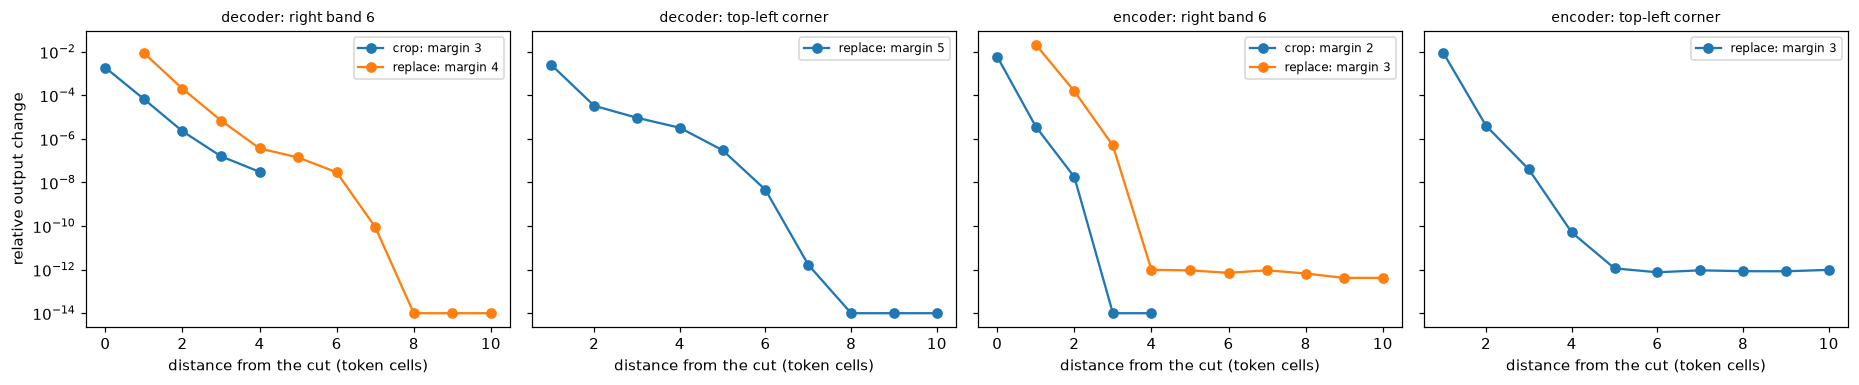

In [24]:
from receptive_field_scope import cut_profile, margin_needed
gh, gw = y.shape[-2:]
corner = torch.zeros(gh, gw, dtype=torch.bool); corner[:6, :6] = True          # top-left 6x6 token corner
cases = [('decoder: right band 6', codec.dec, y, dict(cut=(0, 0, 0, 6))),
         ('decoder: top-left corner', codec.dec, y, dict(replace_mask=corner)),
         ('encoder: right band 6', codec.enc, image, dict(cut=(0, 0, 0, 6))),
         ('encoder: top-left corner', codec.enc, image, dict(replace_mask=corner))]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, (name, fn, inp, kw) in zip(axes, cases):
    with torch.no_grad():
        for mode in ('crop', 'replace'):
            if 'replace_mask' in kw and mode == 'crop':
                continue                                                          # an arbitrary corner can only be replaced, not cropped
            p = cut_profile(fn, inp, mode=mode, maxd=12, **kw)
            ax.semilogy(p['dist'], p['rel_error'].clamp_min(1e-14), 'o-', label=f"{mode}: margin {margin_needed(p, 1e-6)}")
    ax.set_title(name, fontsize=9); ax.set_xlabel('distance from the cut (token cells)'); ax.legend(fontsize=8)
axes[0].set_ylabel('relative output change')
plt.tight_layout()

## 3. How large a hole can be healed?

A centred square hole of 1..6 tokens per side (fill = `neg`). 'Healing' = error versus the original inside the hole relative to the un-lesioned decode.

In [25]:
codec.name

'cheng2020_anchor(quality=6)'

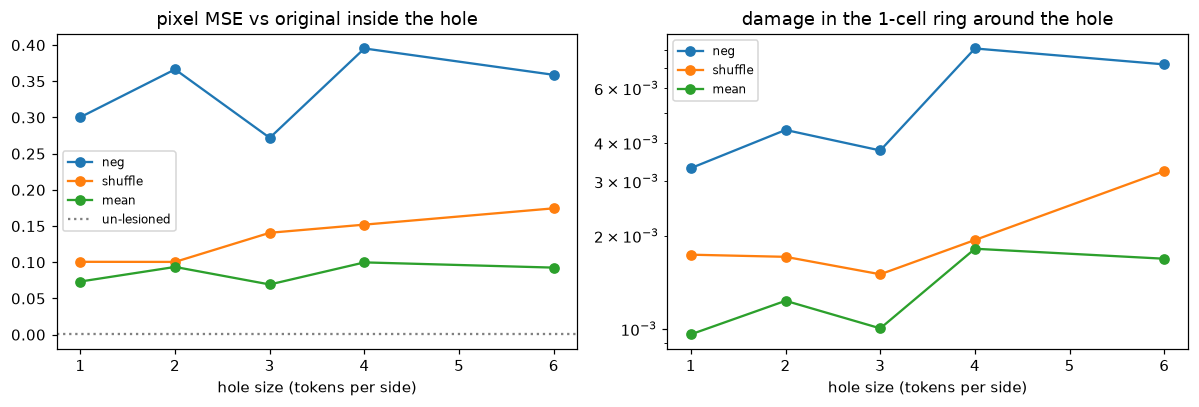

In [26]:
orig = image
sw = {f: hole_sweep(codec.dec, y, sizes=(1, 2, 3, 4, 6), fill=f, quantize=codec.quantize, original=orig) for f in ('neg', 'shuffle', 'mean')}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for f, rows in sw.items():
    ax[0].plot([r['size'] for r in rows], [r['err_inside_lesioned'] for r in rows], 'o-', label=f)
    ax[1].semilogy([r['size'] for r in rows], [r['ring1_damage'] for r in rows], 'o-', label=f)
ax[0].axhline(rows[0]['err_inside_baseline'], color='gray', ls=':', label='un-lesioned')
ax[0].set_title('pixel MSE vs original inside the hole'); ax[1].set_title('damage in the 1-cell ring around the hole')
for a in ax: a.set_xlabel('hole size (tokens per side)'); a.legend(fontsize=8)
plt.tight_layout();

## 4. Is the hole refilled with texture, or just smooth continuation?

Lesion a 3x3-token hole over a textured region and compare, **inside the hole**: the true content (un-lesioned decode); a **content-free** latent fill (`mean`: nothing is written into the hole, so any texture comes from the neighbouring latents' decoder footprints); the **`neighbor`** latent interpolation; and a **smooth pixel-space baseline** (harmonic / Laplace diffusion from the decoded surroundings, which introduces no new texture).
If the latent fills have far more high-frequency power than the smooth baseline, the decoder is extending *texture descriptors* from neighbouring latents, not just continuing values.
(Decoders also ring: judge the look of the crops and the spectrum together, and repeat with other fills.)

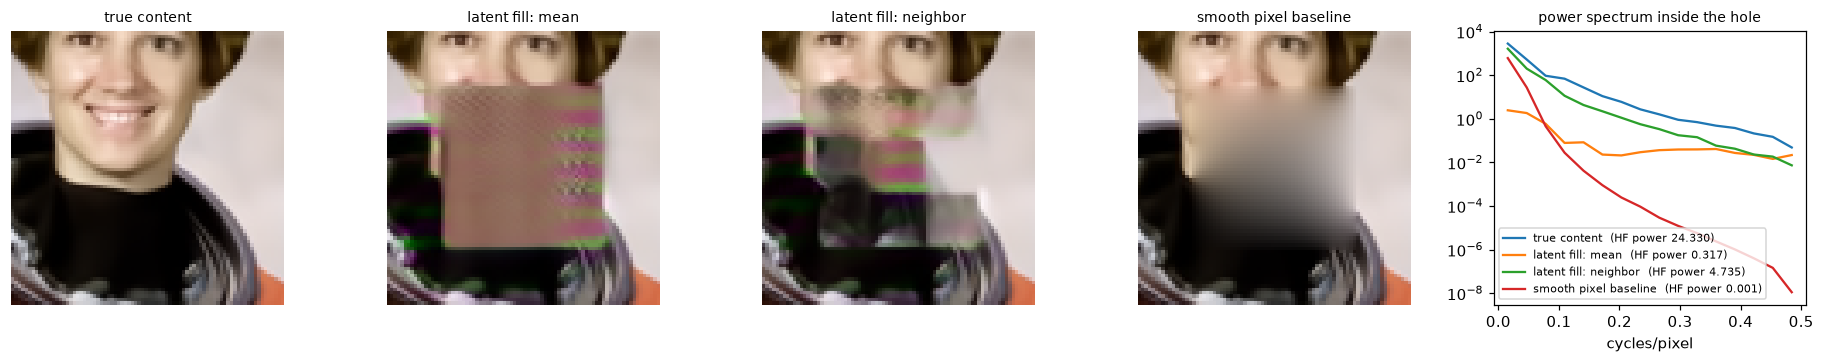

In [27]:
cell = codec.cell
at = (9, 13) if cell == 8 else (4, 6)          # token coords of the hole's top-left; edit for your image
mask_b = make_mask(y.shape[-2:], 'block', size=(3, 3), at=at)
pm = upsample_mask(mask_b, image.shape[-2:])
o_mean = lesion_latents(codec.dec, y, mask_b, 'mean', quantize=codec.quantize)
o_nb = lesion_latents(codec.dec, y, mask_b, 'neighbor', quantize=codec.quantize)
true = o_mean['baseline'][0]
smooth = harmonic_fill(true, pm, iters=600)
ys, xs = (at[0] * cell, (at[0] + 3) * cell), (at[1] * cell, (at[1] + 3) * cell)
pad = cell
crop = lambda t: t[..., max(0, ys[0] - pad):ys[1] + pad, max(0, xs[0] - pad):xs[1] + pad]
inner = lambda t: t[..., ys[0]:ys[1], xs[0]:xs[1]]
panels = [('true content', true), ('latent fill: mean', o_mean['lesioned'][0]), ('latent fill: neighbor', o_nb['lesioned'][0]), ('smooth pixel baseline', smooth)]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, (title, t) in zip(axes[:4], panels):
    ax.imshow(crop(t).permute(1, 2, 0).clamp(0, 1).numpy(), interpolation='nearest'); ax.set_title(title, fontsize=9); ax.axis('off')
for title, t in panels:
    fr, pw = radial_power(inner(t))
    axes[4].semilogy(fr, pw.clamp_min(1e-12), label=f'{title}  (HF power {pw[fr >= 0.15].sum():.3f})')
axes[4].set_xlabel('cycles/pixel'); axes[4].set_title('power spectrum inside the hole', fontsize=9); axes[4].legend(fontsize=7)
plt.tight_layout();

## 5. Which single tokens matter far away? (register hunt)

Lesion every token alone (`neg` fill) and measure the damage **within 2 cells** vs **farther away**. A token whose single-token lesion changes distant pixels carries global information. Local decoders have `far = 0` everywhere (this one should, up to its true reach). On a model with global attention or global normalisation, look for tokens with large far-field damage, often uniform-background tokens.

max far-field damage: 2.44e-06   (max near-field: 2.59e-01)


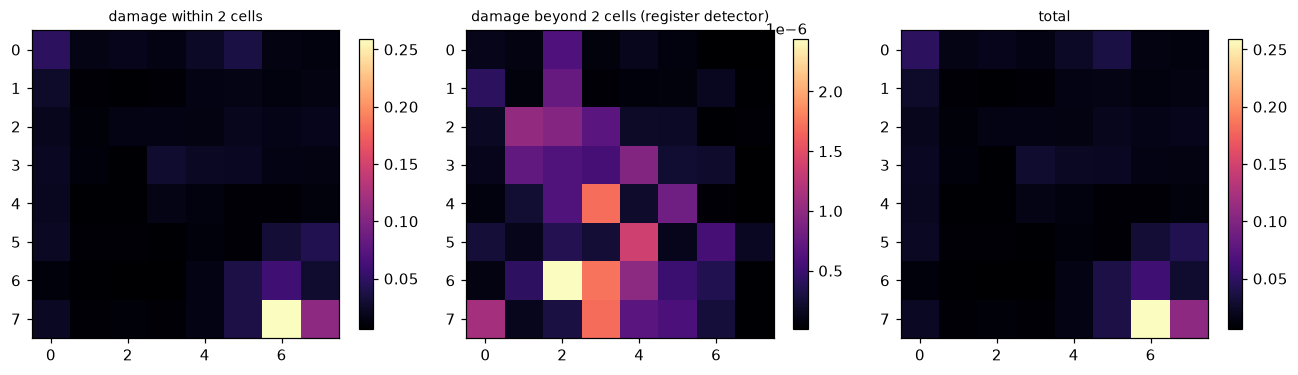

In [28]:
r = lesion_importance_map(codec.dec, y, fill='neg', near=2, step=2, batch=16, quantize=codec.quantize)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, k, t in zip(ax, ['near_map', 'far_map', 'total_map'], ['damage within 2 cells', 'damage beyond 2 cells (register detector)', 'total']):
    im = a.imshow(r[k].numpy(), cmap='magma'); a.set_title(t, fontsize=9); plt.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout()
print(f"max far-field damage: {float(r['far_map'].max()):.2e}   (max near-field: {float(r['near_map'].max()):.2e})")

## Using this on your own models

```python
codec = Codec('my model', model.encoder, model.decoder, quantize=quantizer_or_round, cell=patch_size)
y = codec.enc(image)
# CompressAI mean-scale models: pass the hyperprior means as the fill centre, e.g.  center=means
```
Lesion experiments need only `decode(latents)`, so they work for anything with a decoder: GRN/VAR-style tokenizers, HBQ autoencoders, audio codecs (1D masks need a small extension).